In [1]:
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

## 01. load the dataset

In [5]:
DATA_DIR = Path("../data/FIRE-SMOKE-DATASET/").resolve()

TRAIN_DIR = DATA_DIR / "Train"
TEST_DIR = DATA_DIR / "Test"

classes = ["Fire", "Smoke", "Neutral"]

print("Train exists:", TRAIN_DIR.exists())
print("Test exists:", TEST_DIR.exists())

Train exists: True
Test exists: True


## 02. Extract Histograms

In [10]:
def extract_rgb_histogram(img, bins=16):

    features = []

    for channel in range(3):

        hist = cv2.calcHist(
            [img],
            [channel],
            None,
            [bins],
            [0, 256]
        )

        # Convert counts to proportions
        hist = hist.flatten()
        hist = hist / (hist.sum() + 1e-8)

        features.extend(hist)

    return np.array(features, dtype=np.float32)


def extract_hsv_histogram(img_rgb, bins=16):

    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)

    features = []

    ranges = [(0, 180), (0, 256), (0, 256)]

    for channel, hist_range in enumerate(ranges):

        hist = cv2.calcHist(
            [hsv],
            [channel],
            None,
            [bins],
            hist_range
        )

        hist = hist.flatten()
        hist = hist / (hist.sum() + 1e-8)

        features.extend(hist)

    return np.array(features, dtype=np.float32)

In [7]:
image_path = next((TRAIN_DIR / "Fire").glob("*.jpg"))

img_bgr = cv2.imread(str(image_path))
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

rgb_features = extract_rgb_histogram(img_rgb)

print("RGB feature shape:", rgb_features.shape)
print("RGB features:", rgb_features)

RGB feature shape: (48,)
RGB features: [5.31917453e-01 1.03334658e-01 6.21675253e-02 5.20246141e-02
 3.78721729e-02 2.15561725e-02 1.58793181e-02 1.42913852e-02
 1.31202862e-02 1.34180235e-02 1.25843585e-02 1.42715359e-02
 1.39341010e-02 1.41722905e-02 1.84597056e-02 6.09964281e-02
 7.04704225e-01 1.03294961e-01 2.78682020e-02 2.26875748e-02
 1.93330683e-02 1.53235411e-02 1.23660183e-02 1.15323542e-02
 1.14728063e-02 9.80547816e-03 8.17784853e-03 7.44342990e-03
 7.86026195e-03 8.77332315e-03 1.10559743e-02 1.83009133e-02
 8.57403755e-01 3.60857472e-02 2.27868203e-02 1.65541880e-02
 1.32592302e-02 1.04208020e-02 8.33664183e-03 7.26478780e-03
 6.17308449e-03 5.59745915e-03 4.06907499e-03 3.67209199e-03
 3.71179031e-03 2.58038915e-03 1.66732830e-03 4.16832074e-04]


In [8]:
def extract_color_features(img_rgb):

    rgb = extract_rgb_histogram(img_rgb)
    hsv = extract_hsv_histogram(img_rgb)

    return np.concatenate([rgb, hsv])

In [11]:
features = extract_color_features(img_rgb)

print("Feature shape:", features.shape)
print("Number of features:", len(features))
print("Minimum:", features.min())
print("Maximum:", features.max())

Feature shape: (96,)
Number of features: 96
Minimum: 1.9849147e-05
Maximum: 0.85740376


In [12]:
image_paths = []
labels = []
feature_vectors = []

extensions = {".jpg", ".jpeg", ".png"}

for label, cls in enumerate(classes):

    folder = TRAIN_DIR / cls

    for path in sorted(folder.rglob("*")):

        if path.suffix.lower() not in extensions:
            continue

        img_bgr = cv2.imread(str(path))

        if img_bgr is None:
            continue

        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        features = extract_color_features(img_rgb)

        image_paths.append(str(path))
        labels.append(label)
        feature_vectors.append(features)

X = np.asarray(feature_vectors, dtype=np.float32)
y = np.asarray(labels)

print("Feature matrix:", X.shape)
print("Labels:", y.shape)

Feature matrix: (2700, 96)
Labels: (2700,)


In [13]:
train_idx, val_idx = train_test_split(
    np.arange(len(y)),
    test_size=0.20,
    stratify=y,
    random_state=42
)

X_train = X[train_idx]
X_val = X[val_idx]

y_train = y[train_idx]
y_val = y[val_idx]

print("Train:", X_train.shape)
print("Validation:", X_val.shape)

Train: (2160, 96)
Validation: (540, 96)


In [15]:
FEATURE_DIR = DATA_DIR / "features"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    FEATURE_DIR / "color_features.npz",
    X_train=X_train,
    X_val=X_val,
    y_train=y_train,
    y_val=y_val,
    train_paths=np.array(image_paths)[train_idx],
    val_paths=np.array(image_paths)[val_idx]
)

print("Saved features successfully")

Saved features successfully


## 03. Visualize historgram

Selected image: /Users/sreeramc/Desktop/UC_Berkeley/281/Project_repo/MIDS-281-project/data/FIRE-SMOKE-DATASET/Train/Fire/image_811.jpg


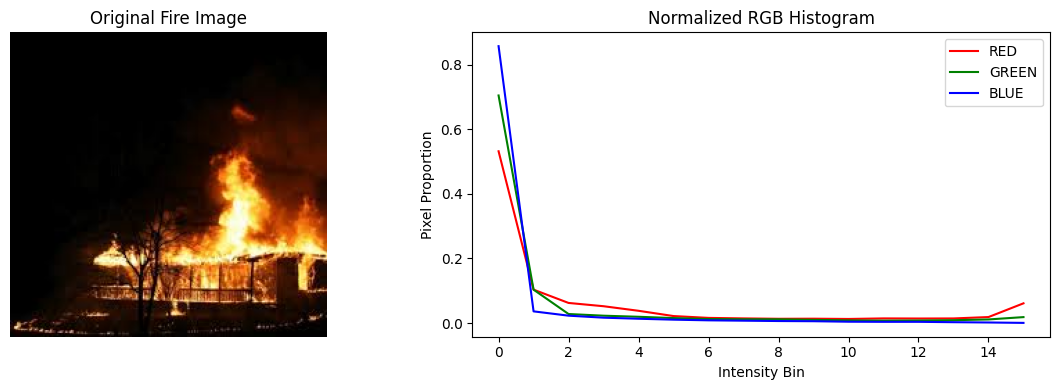

In [24]:
# Load one original Fire image
# Find JPG images inside the Fire folder
fire_images = list((TRAIN_DIR / "Fire").glob("*.jpg"))

# Select first image
image_path = fire_images[0]

print("Selected image:", image_path)

# Read original image
img = cv2.imread(str(image_path))

# Check image loaded successfully
if img is None:
    raise ValueError(f"Could not load image: {image_path}")
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Display original image and RGB histograms
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].imshow(img_rgb)
axes[0].set_title("Original Fire Image")
axes[0].axis("off")

colors = ["red", "green", "blue"]

for channel, color in enumerate(colors):
    hist = cv2.calcHist(
        [img_rgb],
        [channel],
        None,
        [16],
        [0, 256]
    )

    hist = hist.flatten()
    hist = hist / hist.sum()

    axes[1].plot(
        np.arange(16),
        hist,
        color=color,
        label=color.upper()
    )

axes[1].set_title("Normalized RGB Histogram")
axes[1].set_xlabel("Intensity Bin")
axes[1].set_ylabel("Pixel Proportion")
axes[1].legend()

plt.tight_layout()
plt.show()